# J2 — Méthodes de gradient

Objectif : implémenter SGD, Momentum et Adam, puis comparer leur convergence et leurs performances de validation.

## Travaux demandés
- [x] C1 — implémenter SGD, Momentum et Adam
- [x] Enregistrer loss train/validation, norme du gradient et accuracy train/validation
- [x] C2 — comparer vitesse initiale, stabilité, résultats finaux et sensibilité au learning rate

Protocole : garder le même split, la même initialisation et le même budget d’entraînement pour chaque comparaison.


## Contrôle d’une mise à jour
Avant la comparaison sur plusieurs époques, on vérifie que chaque optimiseur fait baisser la loss sur le même batch, avec les mêmes paramètres initiaux.


In [1]:
from data import SEED, generate_data, split_data, standardize_data
from model import init_params, forward, backward
from losses import bce
from optimizers import initialize_state, update_parameters

X, y = generate_data(seed=SEED)
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y, seed=SEED)
X_train, X_val, X_test, mean, std = standardize_data(X_train, X_val, X_test)
y_train = y_train.reshape(-1, 1)
y_val = y_val.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)
X_batch, y_batch = X_train[:32], y_train[:32]

initial_params = init_params(seed=SEED)
y_hat, cache = forward(X_batch, initial_params)
initial_loss = bce(y_hat, y_batch)
grads = backward(y_batch, initial_params, cache)

configs = {
    "sgd": {"learning_rate": 0.1},
    "momentum": {"learning_rate": 1.0, "beta": 0.9},
    "adam": {"learning_rate": 0.01},
}
print("Loss initiale :", initial_loss)
for name, config in configs.items():
    state = initialize_state(name, initial_params)
    updated, state = update_parameters(
        name, initial_params, grads, state, **config
    )
    loss_after = bce(forward(X_batch, updated)[0], y_batch)
    print(f"{name} : {loss_after:.6f}")


Loss initiale : 0.6725602147474747
sgd : 0.651802
momentum : 0.651802
adam : 0.637854


## Résultat du contrôle
Les trois optimiseurs doivent réduire la loss après une mise à jour. Cette vérification valide les formules de mise à jour ; elle ne permet pas encore de comparer leur convergence.

Résultats sur le même batch et la même initialisation : la loss initiale est `0,67256`. Après une mise à jour, elle vaut `0,65180` pour SGD, `0,65180` pour Momentum et `0,63785` pour Adam. Cette vérification confirme que les trois règles de mise à jour font baisser la loss sur ce batch ; elle ne suffit pas à établir quel optimiseur converge le mieux.


## Comparaison expérimentale C2
Les essais ci-dessous utilisent le même split, la même initialisation, le même ordre de mini-batchs et 100 époques. Les learning rates servent de valeurs de départ ; leur sensibilité sera étudiée séparément avec la validation. Le jeu de test n’est pas consulté.


sgd: loss train=0.0803, loss val=0.0857, accuracy val=0.967
momentum: loss train=0.0812, loss val=0.0976, accuracy val=0.970
adam: loss train=0.0770, loss val=0.0948, accuracy val=0.963


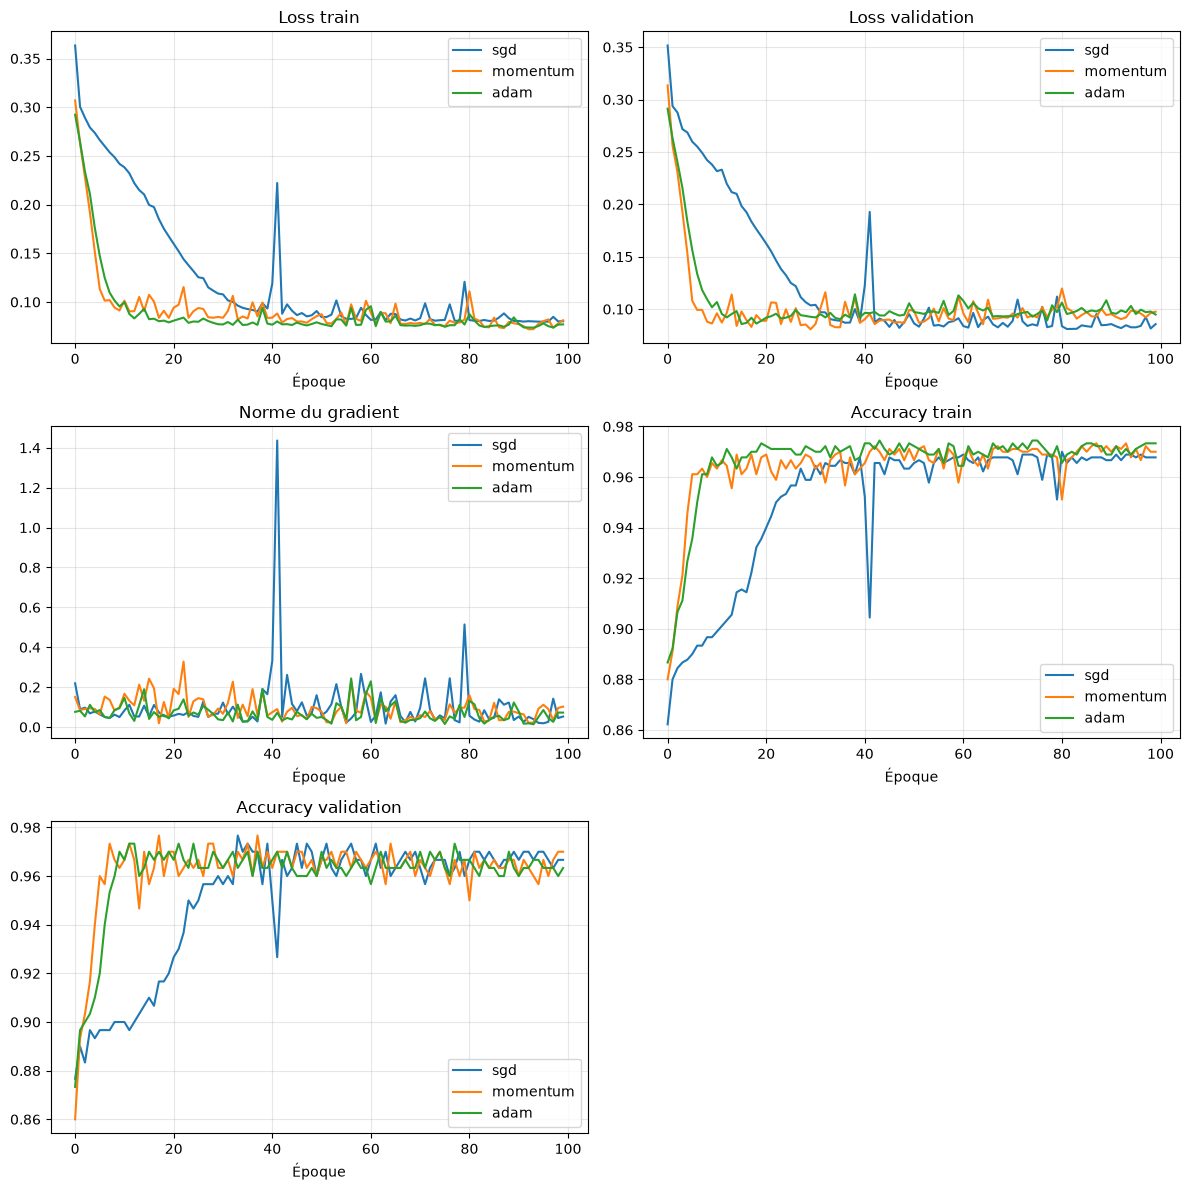

In [2]:


from train import train_model
from plots import plot_optimizer_comparison

train_configs = {
    "sgd": (0.1, {}),
    "momentum": (0.5, {"beta": 0.9}),
    "adam": (0.01, {}),
}
histories = {}
final_params = {}

for name, (learning_rate, optimizer_kwargs) in train_configs.items():
    params = init_params(seed=SEED)
    params, history = train_model(
        X_train, y_train, X_val, y_val, params,
        optimizer=name, learning_rate=learning_rate,
        epochs=100, batch_size=32, seed=SEED,
        optimizer_kwargs=optimizer_kwargs,
    )
    histories[name] = history
    final_params[name] = params
    print(
        f"{name}: loss train={history['train_loss'][-1]:.4f}, "
        f"loss val={history['val_loss'][-1]:.4f}, "
        f"accuracy val={history['val_accuracy'][-1]:.3f}"
    )

plot_optimizer_comparison(histories)


## Sensibilité au learning rate
On compare trois valeurs par optimiseur. Le meilleur réglage est sélectionné selon la loss de validation.


In [3]:
from experiments import compare_learning_rates

learning_rate_grid = {
    "sgd": [0.01, 0.05, 0.1],
    "momentum": [0.1, 0.5, 1.0],
    "adam": [0.001, 0.01, 0.03],
}
sensitivity_results = {}
for name, rates in learning_rate_grid.items():
    sensitivity_results[name] = compare_learning_rates(
        X_train, y_train, X_val, y_val, name, rates,
        epochs=100, batch_size=32, seed=SEED,
        optimizer_kwargs={"beta": 0.9} if name == "momentum" else {},
    )
    for rate, metrics in sensitivity_results[name].items():
        print(
            f"{name}, lr={rate}: val loss={metrics['val_loss']:.4f}, "
            f"val accuracy={metrics['val_accuracy']:.3f}"
        )
    best_rate = min(sensitivity_results[name], key=lambda r: sensitivity_results[name][r]["val_loss"])
    print(f"Meilleur lr {name} selon val loss : {best_rate}\n")


sgd, lr=0.01: val loss=0.2390, val accuracy=0.900
sgd, lr=0.05: val loss=0.0840, val accuracy=0.970
sgd, lr=0.1: val loss=0.0857, val accuracy=0.967
Meilleur lr sgd selon val loss : 0.05

momentum, lr=0.1: val loss=0.0825, val accuracy=0.967
momentum, lr=0.5: val loss=0.0976, val accuracy=0.970
momentum, lr=1.0: val loss=0.1047, val accuracy=0.967
Meilleur lr momentum selon val loss : 0.1

adam, lr=0.001: val loss=0.0967, val accuracy=0.967
adam, lr=0.01: val loss=0.0948, val accuracy=0.963
adam, lr=0.03: val loss=0.1025, val accuracy=0.963
Meilleur lr adam selon val loss : 0.01



## Comparaison avec les learning rates sélectionnés
On réentraîne les trois modèles avec le learning rate qui minimise la loss de validation dans la grille testée, puis on trace leurs courbes.


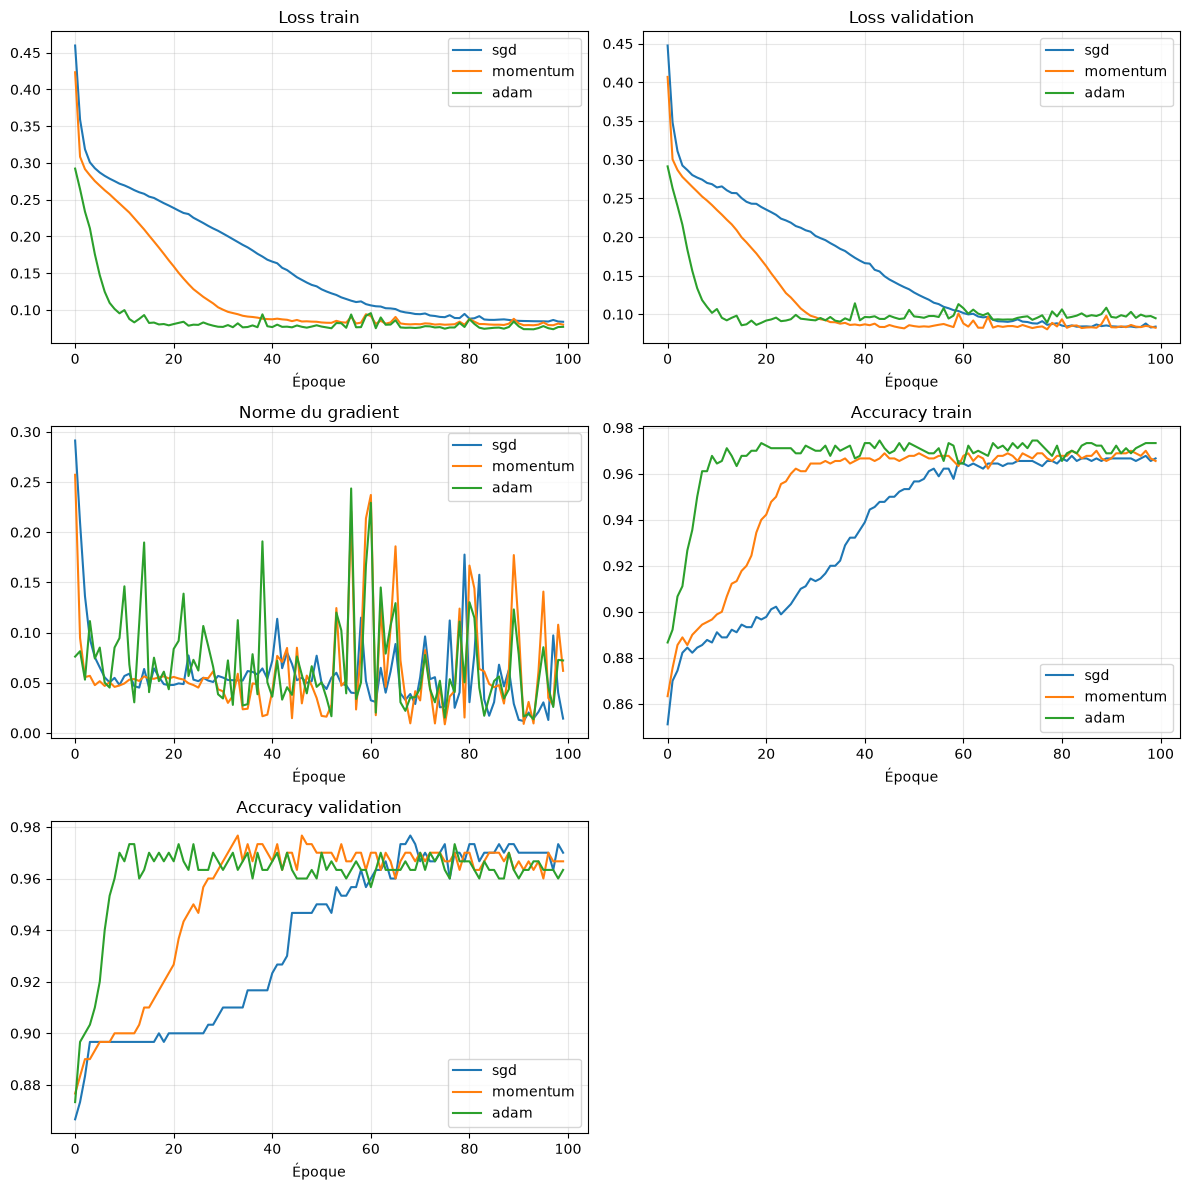

In [4]:
selected_rates = {"sgd": 0.05, "momentum": 0.1, "adam": 0.01}
selected_histories = {}
for name, learning_rate in selected_rates.items():
    params = init_params(seed=SEED)
    _, selected_histories[name] = train_model(
        X_train, y_train, X_val, y_val, params,
        optimizer=name, learning_rate=learning_rate, epochs=100,
        batch_size=32, seed=SEED,
        optimizer_kwargs={"beta": 0.9} if name == "momentum" else {},
    )
plot_optimizer_comparison(selected_histories)


### Analyse C2
Les courbes ci-dessus utilisent les learning rates retenus sur validation : SGD `0,05`, Momentum `0,1`, Adam `0,01`. Adam fait baisser rapidement la loss et atteint une accuracy validation proche de `0,97` dès les premières époques. Momentum progresse ensuite régulièrement ; SGD converge plus lentement. À la fin, les accuracies sont proches (`0,96–0,97`).

Adam atteint la plus faible loss train (`0,0770`), mais sa loss validation finale (`0,0948`) est plus élevée. Momentum obtient la plus faible loss validation (`0,0825`), légèrement devant SGD (`0,0840`). Les losses train et validation restent proches, sans signe net de sur-apprentissage sur ces courbes. L’accuracy seule différencie peu les modèles : la BCE révèle des différences dans la qualité des probabilités, même quand les classes prédites sont les mêmes.

La norme du gradient fluctue fortement, avec plusieurs pics, surtout pour Momentum et Adam. Ces pics ne s’accompagnent pas d’une hausse durable de la loss validation ni d’une chute durable de l’accuracy ; l’entraînement reste donc globalement stable, malgré des mises à jour irrégulières. Les mises à jour par mini-batch peuvent contribuer à ces fluctuations.

Le balayage testé sélectionne SGD `0,05`, Momentum `0,1` et Adam `0,01` selon la loss validation. Le classement dépend de la seed et de la grille explorée ; le jeu de test n’a pas servi au choix et reste réservé à l’évaluation finale.
